# 05 – Multi-season WAR

**Goal:** run the v0.3 model on five seasons (2021-22 through 2025-26) and use that history to answer two questions:
1. **Which parts of the model are real skill, and which are mostly noise?** A stat that measures skill should look similar for the same player from one season to the next.
2. **Is Cole Caufield's #2 ranking real?** One season couldn't tell us. Five can.

The model now lives in `src/war_model.py`, so the same code runs on every season. Notebooks 01–04 stay as the record of how it was built.

Data: MoneyPuck.com season-level skater files, one per season, saved in `data/` as `skaters21-22.csv` through `skaters25-26.csv`.

## 1. Setup

In [ ]:
import sys
sys.path.append("../src")          # lets the notebook import war_model.py

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from war_model import run_season, rate60, COMPONENTS

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

DATA = Path("../data")
IMAGES = Path("../images")

SEASONS = {2021: "21-22", 2022: "22-23", 2023: "23-24", 2024: "24-25", 2025: "25-26"}

## 2. Check: does `war_model.py` reproduce v0.3 exactly?
Before trusting the reusable version, confirm it gives the same numbers as notebook 04. The differences should be essentially zero (tiny values like 1e-15 are just computer rounding).

In [ ]:
check_new = run_season(DATA / "skaters25-26.csv")
check_old = pd.read_csv(DATA / "war_v03.csv")

merged = check_old[["playerId", "war"]].merge(check_new[["playerId", "war"]], on="playerId", suffixes=("_v03", "_module"))
print("Players matched:", len(merged), "of", len(check_old))
print("Largest WAR difference:", float((merged["war_v03"] - merged["war_module"]).abs().max()))

Players matched: 940 of 940
Largest WAR difference: 1.3322676295501878e-15


## 3. Run every season

In [ ]:
seasons = [run_season(DATA / f"skaters{label}.csv") for label in SEASONS.values()]
all_seasons = pd.concat(seasons, ignore_index=True)

print(all_seasons.groupby("season").size().rename("skaters"))

season
2021    1003
2022     951
2023     924
2024     920
2025     940
Name: skaters, dtype: int64


### Top 5 by season
A quick sanity check: the leaders should be players who were widely seen as elite that year.

In [ ]:
for season, group in all_seasons.groupby("season"):
    top = group.nlargest(5, "war")[["name", "team", "position", "war"]].round(2)
    print(f"{season}-{str(season + 1)[-2:]}")
    print(top.to_string(index=False))
    print()

2021-22
           name team position  war
Auston Matthews  TOR        C 5.77
 Connor McDavid  EDM        C 5.60
Matthew Tkachuk  CGY        L 4.83
Johnny Gaudreau  CGY        L 4.77
   Sam Reinhart  FLA        C 4.01

2022-23
           name team position  war
 Connor McDavid  EDM        C 6.63
 Leon Draisaitl  EDM        C 4.82
   John Tavares  TOR        C 4.52
Matthew Tkachuk  FLA        L 4.38
Auston Matthews  TOR        C 4.28

2023-24
            name team position  war
 Auston Matthews  TOR        C 5.58
  Connor McDavid  EDM        C 5.17
Nathan MacKinnon  COL        C 4.65
      Zach Hyman  EDM        L 4.28
    Sam Reinhart  FLA        C 4.06

2024-25
           name team position  war
     Cale Makar  COL        D 4.32
  Zach Werenski  CBJ        D 3.99
 Connor McDavid  EDM        C 3.88
Auston Matthews  TOR        C 3.72
 Leon Draisaitl  EDM        C 3.47

2025-26
            name team position  war
  Connor McDavid  EDM        C 5.11
   Cole Caufield  MTL        R 3.99
  

## 4. Two tests for every stat
A stat belongs in WAR only if it passes **two separate tests**:
1. **Is it repeatable?** If a player's number in one season predicts his number the next season, it mostly reflects the player (skill or role). If it bounces around, it's mostly luck.
2. **Is it valuable?** Does it predict **winning**? Here, "winning" is the player's **relative goal differential** the next season: even-strength goals for minus goals against per 60 with him on the ice, compared to his team without him.

Repeatable is not the same as valuable. A stat can describe a player's role very consistently and still have nothing to do with winning.

Each test is a **correlation (r)** across every player with 500+ even-strength minutes in back-to-back seasons. **Forwards and defensemen are tested separately.** Mixing them inflates the numbers, because forwards out-shoot and out-score defensemen every year no matter how good they are.

### Extra stats from the raw files (hits, blocks, shots, takeaways, on-ice goals)

In [ ]:
EXTRA = ["I_F_points", "I_F_shotsOnGoal", "I_F_hits", "shotsBlockedByPlayer", "I_F_takeaways",
         "OnIce_F_goals", "OnIce_A_goals", "onIce_corsiPercentage"]

extra = []
for label in SEASONS.values():
    raw = pd.read_csv(DATA / f"skaters{label}.csv")
    ev = raw.loc[raw["situation"] == "5on5", ["playerId", "season"] + EXTRA]
    extra.append(ev.rename(columns={c: f"ev_{c}" for c in EXTRA}))
extra = pd.concat(extra, ignore_index=True)

df = all_seasons.merge(extra, on=["playerId", "season"], how="left")
toi = df["ev_toi"]

df["p1_60"]   = rate60(df["ev_I_F_goals"] + df["ev_I_F_primaryAssists"], toi)
df["pts_60"]  = rate60(df["ev_I_F_points"], toi)
df["g_60"]    = rate60(df["ev_I_F_goals"], toi)
df["ixg_60"]  = rate60(df["ev_I_F_xGoals"], toi)
df["sog_60"]  = rate60(df["ev_I_F_shotsOnGoal"], toi)
df["sh_pct"]  = np.where(df["ev_I_F_shotsOnGoal"] > 0, df["ev_I_F_goals"] / df["ev_I_F_shotsOnGoal"], np.nan)
df["fin_60"]  = rate60(df["ev_I_F_goals"] - df["ev_I_F_xGoals"], toi)
df["hits_60"] = rate60(df["ev_I_F_hits"], toi)
df["blk_60"]  = rate60(df["ev_shotsBlockedByPlayer"], toi)
df["take_60"] = rate60(df["ev_I_F_takeaways"], toi)
df["cf_pct"]  = df["ev_onIce_corsiPercentage"]
df["war_82"]  = df["war"] / df["games_played"] * 82

# Relative goal differential. Team 5v5 goals = sum of every skater's on-ice goals / 5 (five skaters on the ice).
team = df.groupby(["season", "team"])[["ev_OnIce_F_goals", "ev_OnIce_A_goals"]].transform("sum") / 5
on_gd  = df["ev_OnIce_F_goals"] - df["ev_OnIce_A_goals"]
off_gd = (team["ev_OnIce_F_goals"] - df["ev_OnIce_F_goals"]) - (team["ev_OnIce_A_goals"] - df["ev_OnIce_A_goals"])
df["rel_gd_60"] = rate60(on_gd, toi) - rate60(off_gd, df["ev_bench_toi"])

In [ ]:
METRICS = {
    "p1_60":         "Primary points (G + A1)",
    "pts_60":        "All points",
    "g_60":          "Goals",
    "ixg_60":        "Expected goals (ixG)",
    "sog_60":        "Shots on goal",
    "sh_pct":        "Shooting %",
    "fin_60":        "Finishing (G minus xG)",
    "hits_60":       "Hits",
    "blk_60":        "Blocked shots",
    "take_60":       "Takeaways",
    "cf_pct":        "On-ice Corsi %",
    "ev_rel_xga_60": "EV defense (model)",
    "war_82":        "WAR per 82 games",
    "rel_gd_60":     "Relative goal diff",
}

qualified = df[df["ev_toi"] >= 500]
pairs = []
for season in sorted(qualified["season"].unique())[:-1]:
    year1 = qualified[qualified["season"] == season]
    year2 = qualified[qualified["season"] == season + 1]
    pairs.append(year1.merge(year2, on="playerId", suffixes=("_y1", "_y2")))
pairs = pd.concat(pairs, ignore_index=True)
pairs["pos"] = pairs["pos_group_y1"]

rows = []
for m, label in METRICS.items():
    row = {"stat": label}
    for pos, name in [("F", "Forwards"), ("D", "Defense")]:
        g = pairs[pairs["pos"] == pos]
        row[f"{name}: repeatable"] = g[f"{m}_y1"].corr(g[f"{m}_y2"])
        row[f"{name}: valuable"] = g[f"{m}_y1"].corr(g["rel_gd_60_y2"])
    rows.append(row)
tests = pd.DataFrame(rows).set_index("stat")

print("Player-season pairs:", pairs["pos"].value_counts().to_dict())
tests.sort_values("Forwards: valuable", ascending=False).round(2)

Player-season pairs: {'F': 1265, 'D': 707}


,Forwards: repeatable,Forwards: valuable,Defense: repeatable,Defense: valuable
stat,,,,
All points,0.54,0.33,0.44,0.23
Primary points (G + A1),0.53,0.32,0.42,0.21
WAR per 82 games,0.66,0.32,0.56,0.25
Goals,0.40,0.25,0.32,0.15
Relative goal diff,0.25,0.25,0.15,0.15
Shots on goal,0.78,0.22,0.74,0.12
On-ice Corsi %,0.65,0.20,0.57,0.16
Finishing (G minus xG),0.28,0.18,0.07,0.08
Expected goals (ixG),0.63,0.17,0.65,0.16


**How to read this:** "repeatable" = this season's stat vs. next season's same stat. "Valuable" = this season's stat vs. next season's relative goal differential. Relative goal differential itself only repeats at about 0.25 for forwards, because goals are rare and noisy. That is why plus-minus alone can't rate players, and why the "valuable" numbers are all modest. Compare them to each other, not to 1.

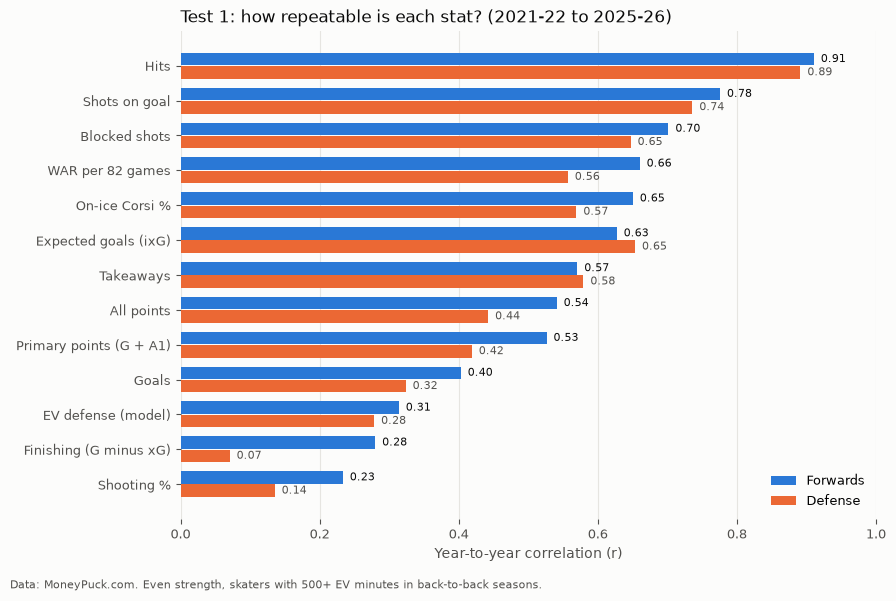

In [ ]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE = "#2a78d6", "#eb6834"   # forwards, defense

def clean_axes(ax):
    ax.set_facecolor(SURFACE)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)

# Chart 1: repeatability, forwards vs defense
plot = tests[["Forwards: repeatable", "Defense: repeatable"]].drop("Relative goal diff")
plot = plot.sort_values("Forwards: repeatable")
y = np.arange(len(plot))
fig, ax = plt.subplots(figsize=(9, 6), facecolor=SURFACE)
clean_axes(ax)
ax.barh(y + 0.19, plot["Forwards: repeatable"], height=0.36, color=BLUE, label="Forwards")
ax.barh(y - 0.19, plot["Defense: repeatable"], height=0.36, color=ORANGE, label="Defense")
for i, (f, d) in enumerate(plot.values):
    ax.text(max(f, 0) + 0.01, i + 0.19, f"{f:.2f}", va="center", fontsize=8, color=INK)
    ax.text(max(d, 0) + 0.01, i - 0.19, f"{d:.2f}", va="center", fontsize=8, color=MUTED)
ax.set_yticks(y, plot.index)
ax.set_xlim(0, 1)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_xlabel("Year-to-year correlation (r)", color=MUTED)
ax.set_title("Test 1: how repeatable is each stat? (2021-22 to 2025-26)", loc="left", color=INK, fontsize=12)
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.text(0.01, 0.01, "Data: MoneyPuck.com. Even strength, skaters with 500+ EV minutes in back-to-back seasons.", fontsize=8, color=MUTED)
plt.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(IMAGES / "repeatability.png", dpi=150, facecolor=SURFACE)
plt.show()

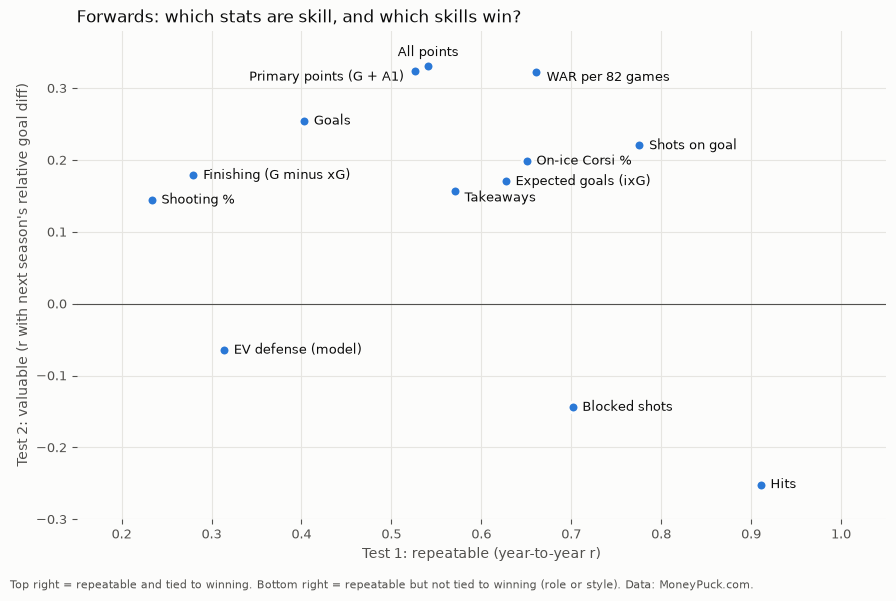

In [ ]:
# Chart 2: skill vs. value, forwards
fwd = tests[["Forwards: repeatable", "Forwards: valuable"]].drop("Relative goal diff")
fig, ax = plt.subplots(figsize=(9, 6), facecolor=SURFACE)
clean_axes(ax)
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.grid(color=GRID, linewidth=0.8)
ax.scatter(fwd["Forwards: repeatable"], fwd["Forwards: valuable"], s=60, color=BLUE,
           edgecolor=SURFACE, linewidth=2, zorder=3)
# A few labels sit close together, so nudge them apart
NUDGE = {"All points": (0, 10, "center"), "Primary points (G + A1)": (-8, -4, "right"), "WAR per 82 games": (8, -4, "left"), "Takeaways": (7, -5, "left")}
for label, (x, yv) in fwd.iterrows():
    dx, dy, ha = NUDGE.get(label, (7, 0, "left"))
    ax.annotate(label, (x, yv), xytext=(dx, dy), textcoords="offset points", ha=ha, va="center", fontsize=9, color=INK)
ax.set_xlim(0.15, 1.05)
ax.set_ylim(-0.3, 0.38)
ax.set_xlabel("Test 1: repeatable (year-to-year r)", color=MUTED)
ax.set_ylabel("Test 2: valuable (r with next season's relative goal diff)", color=MUTED)
ax.set_title("Forwards: which stats are skill, and which skills win?", loc="left", color=INK, fontsize=12)
fig.text(0.01, 0.01, "Top right = repeatable and tied to winning. Bottom right = repeatable but not tied to winning (role or style). Data: MoneyPuck.com.",
         fontsize=8, color=MUTED)
plt.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(IMAGES / "skill_vs_value.png", dpi=150, facecolor=SURFACE)
plt.show()

### Predicting next season's goals: actual, expected, or both?
For forwards: does last season's goal rate or expected goal rate better predict next season's goals? And does blending them beat either one?

In [ ]:
f = pairs[pairs["pos"] == "F"].dropna(subset=["g_60_y1", "ixg_60_y1", "g_60_y2"])
X = np.column_stack([np.ones(len(f)), f["g_60_y1"], f["ixg_60_y1"]])
coef = np.linalg.lstsq(X, f["g_60_y2"], rcond=None)[0]
blend = X @ coef

print(f"Last season's goals/60          -> next season's goals/60: r = {f['g_60_y1'].corr(f['g_60_y2']):.2f}")
print(f"Last season's expected goals/60 -> next season's goals/60: r = {f['ixg_60_y1'].corr(f['g_60_y2']):.2f}")
print(f"Blend of both                   -> next season's goals/60: r = {np.corrcoef(blend, f['g_60_y2'])[0, 1]:.2f}")
print(f"Blend weights: goals {coef[1]:.2f}, expected goals {coef[2]:.2f}")

Last season's goals/60          -> next season's goals/60: r = 0.40
Last season's expected goals/60 -> next season's goals/60: r = 0.34
Blend of both                   -> next season's goals/60: r = 0.43
Blend weights: goals 0.31, expected goals 0.30


## 5. The Caufield question
In v0.3, Caufield ranked #2 largely because he scored 33 even-strength goals on about 18 expected. The first guess was that this was mostly luck. Five seasons can test that.

In [ ]:
caufield = df[df["name"] == "Cole Caufield"].copy()
caufield["goals_minus_xg"] = caufield["ev_I_F_goals"] - caufield["ev_I_F_xGoals"]
caufield[["season", "team", "games_played", "ev_I_F_goals", "ev_I_F_xGoals", "goals_minus_xg", "war", "war_rank"]].round(2)

,season,team,games_played,ev_I_F_goals,ev_I_F_xGoals,goals_minus_xg,war,war_rank
836,2021,MTL,67,15.0,11.43,3.57,0.72,194
1807,2022,MTL,46,17.0,9.58,7.42,0.69,187
2811,2023,MTL,82,16.0,17.20,-1.20,1.77,61
3483,2024,MTL,82,26.0,18.81,7.19,2.35,28
4731,2025,MTL,81,33.0,18.07,14.93,3.99,2


In [ ]:
total = caufield[["ev_I_F_goals", "ev_I_F_xGoals"]].sum()
print(f"Five seasons combined: {total['ev_I_F_goals']:.0f} EV goals on {total['ev_I_F_xGoals']:.1f} expected "
      f"({total['ev_I_F_goals'] - total['ev_I_F_xGoals']:+.1f})")

Five seasons combined: 107 EV goals on 75.1 expected (+31.9)


**Verdict:** finishing has low repeatability across the league, but Caufield beat expected in 4 of 5 seasons. That's a real finisher, not one lucky year. One season of finishing should count for little; five seasons should count for a lot. That's the shrinkage idea in v0.4.

## 6. Stars across seasons

In [ ]:
STARS = ["Connor McDavid", "Nathan MacKinnon", "Auston Matthews", "Leon Draisaitl", "Cale Makar",
         "Cole Caufield", "Lane Hutson"]

(df[df["name"].isin(STARS)]
   .pivot_table(index="name", columns="season", values="war_rank", aggfunc="first")
   .reindex(STARS))

season,2021,2022,2023,2024,2025
name,,,,,
Connor McDavid,2.0,1.0,2.0,3.0,1.0
Nathan MacKinnon,11.0,17.0,3.0,23.0,4.0
Auston Matthews,1.0,5.0,1.0,4.0,57.0
Leon Draisaitl,6.0,2.0,26.0,5.0,5.0
Cale Makar,19.0,20.0,22.0,1.0,10.0
Cole Caufield,194.0,187.0,61.0,28.0,2.0
Lane Hutson,NaN,NaN,375.0,131.0,9.0


## 7. Save
`war_by_season.csv` has every skater's WAR and components for all five seasons. This is the base table for the player cards and for aging curves later.

In [ ]:
keep = ["season", "playerId", "name", "team", "position", "pos_group", "games_played",
        "all_toi", "ev_toi", "pp_toi", "pk_toi"] + COMPONENTS + ["gar", "war", "war_rank"]
all_seasons[keep].to_csv(DATA / "war_by_season.csv", index=False)
print("Saved", len(all_seasons), "player-seasons to data/war_by_season.csv")

Saved 4738 player-seasons to data/war_by_season.csv


## Takeaways for v0.4
**Skill vs. value (section 4)**
- **Points matter more than the model gave them credit for.** For forwards, primary points and all points are the best single predictors of next season's goal differential (r ≈ 0.32), as good as WAR itself. Expected goals are more repeatable but less tied to winning.
- **Blend results with process.** Last season's actual goals predict next season's goals better than expected goals do, and a roughly 50/50 blend beats both. Finishing is part skill, part luck.
- **Hits and blocks are repeatable but not valuable.** Hits are the most repeatable stat tested (0.91 for forwards) and are *negatively* tied to next season's goal differential. They measure role: players who hit and block a lot are usually chasing the puck. They belong on the player card as style, not in WAR.
- **The EV defense component fails test 2.** It repeats only around 0.3 and does not predict next season's goal differential for forwards. This is the biggest weakness in v0.3.

**Caufield (section 5)**
- Above expected in 4 of 5 seasons, +32 goals combined. A real finisher, not one lucky season. The model should give proven finishers more finishing credit than one-season outliers.

**v0.4 plan**
1. Multi-season finishing with shrinkage: credit scales with how many shots of evidence a player has.
2. Rebuild or down-weight the EV defense component.
3. Benchmark: v0.4 WAR must predict next season's relative goal differential better than primary points alone (r ≈ 0.32 for forwards). Right now it only ties.